# **TS5:** Estimación Espectral

García Corona, Iara Paula

### Introducción
Este trabajo propone estimar la PSD de tres tipos de señales (electrocardiograma, fotopletismografía y audio) para luego estimar y comparar el ancho de banda de cada una. <br>
La PSD descibe cómo se distribuye la potencia de una señal en función de la frecuencia. Para esto se define como la transformada de Fourier de la autocorrelación de la señal: $$S_{xx}=\sum_{l=-\infty}^{\infty}r_{xx}[l]e^{-j\omega l}$$ El estimador no paramétrico más básico es el periodograma, que consiste en calcular la DFT de la señal (por defecto python aplica la ventana rectangular) y por último elevar el módulo del resultado al cuadrado y normalizar. Aunque resulta ser un método asintóticamente insesgado, no es consistente ya que su varianza no disminuye cuando las muestras tienen a $\infty$. Para tratar este problema se implementa el método Welch, que consiste en dividir la señal en $M$ segmentos efectivos de $L=\frac{N}{K}$ muestras, que se solapan $D$ muestras entre sí, multiplica cada segmento por una ventana $w_L[n]$ y promedia los periodogramas resultantes.<br>
En este proyecto se implementó $\texttt{scipy.signal.welch}$, con los valores por defecto: Ventana Hann y solapamiento del $50\%$, con $D=\frac{L}{2}$. Con estas características, la varianza del método es aproximadamente la mitad que la del promedio de periodogramas sin solapar.<br>
Para una señal de $N$ muestras, la cantidad de segmentos determina el largo de cada uno y por lo tanto se obtiene la resolución espectral: $$\Delta f=\frac{f_s}{L}=\frac{K}{T}$$ donde $K$ es la cantidad de partes en las que se divide la señal ($M$ es la cantidad de segmentos que efectivamente se promedian gracias al solapamiento), y $T$ la duración del registro. Acá se ve otro inconveniente que requiere considerar el balance, más segmentos reducen la varianza pero empeoran la resolución, porque cada segmento es más corto, dando un $\Delta_f$ mayor, por lo que se suaviza la curva final. Para cada señal se compararon distintas cantidades de segmentos y se buscó un valor intermedio entre la pérdida de resolución y la alta varianza.<br>
Para estimar el ancho de banda se tomó la frecuencia por debajo de la que se acumula el $99\%$ de la potencia total de la señal. Para esto se calculó la potencia acumulada de la señal normalizada:<br>
$$P_{acum}[k]=\frac{\sum_{i=0}^{k}P_W(f_i)}{\sum_{i=0}^{\frac{L}{2}}P_W(f_i)}$$  y luego se buscó la primera frecuencia para la cual laa potencia acumulada alcanza el $99\%$.

Se importan las librerías que se van a utilizar a lo largo de todo el programa:

In [1]:
import numpy as np
from scipy import signal as sig
import matplotlib.pyplot as plt   
import scipy.io as sio
import pandas as pd

### ECG
Se plantea el código para la toma de datos del *ECG* y su análisis:

In [2]:
#%% ECG
##################
# Lectura de ECG #
##################
fs_ecg = 1000 # Hz

##################
## ECG sin ruido
##################

ecg=np.load('ecg_sin_ruido.npy')

#nperseg:largo de cada segmento.
frec_ecg_8,pxx_ecg_8=sig.welch(ecg,fs_ecg,nperseg=len(ecg)//8)#Da segmentos de tamaño entero
frec_ecg_10,pxx_ecg_10=sig.welch(ecg,fs_ecg,nperseg=len(ecg)//10)#Da segmentos de tamaño entero
frec_ecg_15,pxx_ecg_15=sig.welch(ecg,fs_ecg,nperseg=len(ecg)//15)#Da segmentos de tamaño entero

pxx_db_ecg_8=10*np.log10(pxx_ecg_8)
pxx_db_ecg_10=10*np.log10(pxx_ecg_10)
pxx_db_ecg_15=10*np.log10(pxx_ecg_15)

#%%% Ancho de Banda
#Devuelve la suma de valores a lo largo de un vector
pot_acum_nor_ecg_8=np.cumsum(pxx_ecg_8)/np.sum(pxx_ecg_8) #Suma acumulativa en un vector/suma total. Lo normaliza
ancho_ecg_8=frec_ecg_8[np.argmax(pot_acum_nor_ecg_8>=0.99)]

pot_acum_nor_ecg_15=np.cumsum(pxx_ecg_15)/np.sum(pxx_ecg_15) #Suma acumulativa en un vector/suma total. Lo normaliza
ancho_ecg_15=frec_ecg_15[np.argmax(pot_acum_nor_ecg_15>=0.99)]

pot_acum_nor_ecg_10=np.cumsum(pxx_ecg_10)/np.sum(pxx_ecg_10) #Suma acumulativa en un vector/suma total. Lo normaliza
ancho_ecg_10=frec_ecg_10[np.argmax(pot_acum_nor_ecg_10>=0.99)]

Se estimó su PSD con el método de Welch para distintos $K$ hasta obtener tres valores convenientes para realizar la elección. Para esta señal se tomaron los $K=8$, $10$ y $15$:<br>
* $K=8\phantom{1}\quad \rightarrow \quad L=3750$
* $K=10\quad \rightarrow \quad L=3000$
* $K=15\quad \rightarrow \quad L=2000$
<br>Al aumentar $K$, se promedian más periodogramas y la estimación se vuelve menos ruidosa (menor varianza), pero los segmentos son más cortos por lo que la respuesta se ve suavizada, perdiendo detalles. Se tomó el valor intermedio, $K=10$, que es el compromiso entre la resolución y la varianza.<br>
La PSD en python devuelve los valores en unidades lineales de potencia, por lo que para poder tener una gráfica útil para el análisis se expresó en $dB$ $\left( 10\cdot \log_{10} \left(P_W\right)\right).$<br>
Por último, para cada estimación se calculó la potencia acumulada normalizada $P_{acum} [k]$ y se tomó como ancho de banda la primera frecuencia en la que la curva alcanza el $99\%$.

Se generan los gráficos con los cuales se define el $K$. Una vez hecho el análisis se seleccionó el valor y en las imágenes que se encuentran a continuación se agrega una línea punteada para señalar el ancho de banda correspondiente al $K$ elegido:

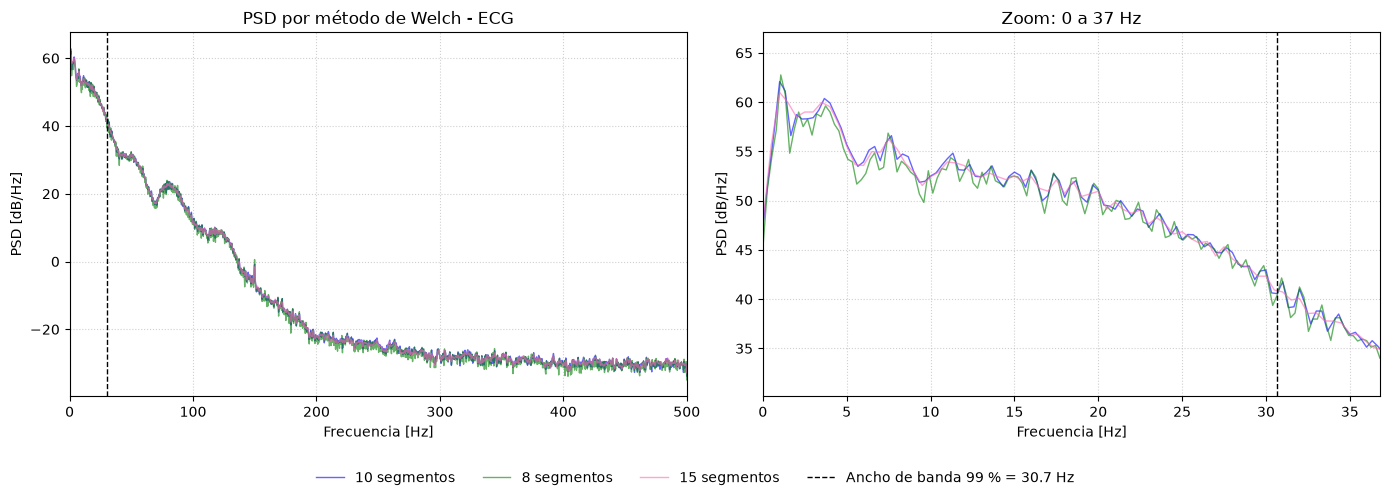

In [3]:
# Límite superior del zoom [Hz]
f_ecg_zoom = 1.2 * ancho_ecg_10
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for ax in (ax1, ax2):
    ax.plot(frec_ecg_10, pxx_db_ecg_10, color='blue', linewidth=1, alpha=0.6, label="10 segmentos")
    ax.plot(frec_ecg_8, pxx_db_ecg_8, color='green', linewidth=1, alpha=0.6, label="8 segmentos")
    ax.plot(frec_ecg_15, pxx_db_ecg_15, color='hotpink', linewidth=1, alpha=0.6, label="15 segmentos")
    ax.axvline(ancho_ecg_10, color='k', linestyle='--', linewidth=1,
               label=f'Ancho de banda 99 % = {ancho_ecg_10:.1f} Hz')
    ax.set_xlabel('Frecuencia [Hz]')
    ax.set_ylabel('PSD [dB/Hz]')
    ax.grid(True, linestyle=':', alpha=0.6)

# Gráfico 1: espectro completo
ax1.set_title('PSD por método de Welch - ECG')
ax1.set_xlim(0, fs_ecg / 2)

# Gráfico 2: zoom en los primeros picos
ax2.set_title(f'Zoom: 0 a {f_ecg_zoom:.0f} Hz')
ax2.set_xlim(0, f_ecg_zoom)
mask = frec_ecg_10 <= f_ecg_zoom   # reajusta el eje y al rango visible
ax2.set_ylim(pxx_db_ecg_10[mask].min() - 5, pxx_db_ecg_10[mask].max() + 5)

# Para poner una única leyenda debajo de los gráficos porque sino tapa información
handles, labels = ax1.get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=len(labels), frameon=False)
fig.tight_layout(rect=[0, 0.08, 1, 1])   # Para que la leyenda no quede pegada a los ejes
plt.show()

ancho_ecg_selec=ancho_ecg_10

En el detalle de 0 a 37Hz se observa que la estimación con $K=8$ tiene una myor cantidad de picos mientras que la de $K=15$ resulta más suale. La curva de $K=10$ se ubica entre ambas y el ancho de banda obtenido es de $30,7Hz$

### PPG
Se plantea el código para la toma de datos del *PPG* y su análisis:

In [17]:
#%% PPG

####################################
# Lectura de pletismografía (PPG)  #
####################################

fs_ppg = 400 # Hz

##################
## PPG sin ruido
##################
ppg = np.load('ppg_sin_ruido.npy')
#print(fs_ppg/(len(ppg)//8))

#nperseg:largo de cada segmento.
frec_ppg_8,pxx_ppg_8=sig.welch(ppg,fs_ppg,nperseg=len(ppg)//8)#Da segmentos de tamaño entero
frec_ppg_10,pxx_ppg_10=sig.welch(ppg,fs_ppg,nperseg=len(ppg)//10)#Da segmentos de tamaño entero
frec_ppg_5,pxx_ppg_5=sig.welch(ppg,fs_ppg,nperseg=len(ppg)//5)#Da segmentos de tamaño entero
pxx_db_ppg_8=10*np.log10(pxx_ppg_8)
pxx_db_ppg_10=10*np.log10(pxx_ppg_10)
pxx_db_ppg_5=10*np.log10(pxx_ppg_5)

#%%% Ancho de Banda
#Devuelve la suma de valores a lo largo de un vector
pot_acum_nor_ppg_8=np.cumsum(pxx_ppg_8)/np.sum(pxx_ppg_8) #Suma acumulativa en un vector/suma total. Lo normaliza
ancho_ppg_8=frec_ppg_8[np.argmax(pot_acum_nor_ppg_8>=0.99)]

pot_acum_nor_ppg_5=np.cumsum(pxx_ppg_5)/np.sum(pxx_ppg_5) #Suma acumulativa en un vector/suma total. Lo normaliza
ancho_ppg_5=frec_ppg_5[np.argmax(pot_acum_nor_ppg_5>=0.99)]

pot_acum_nor_ppg_10=np.cumsum(pxx_ppg_10)/np.sum(pxx_ppg_10) #Suma acumulativa en un vector/suma total. Lo normaliza
ancho_ppg_10=frec_ppg_10[np.argmax(pot_acum_nor_ppg_10>=0.99)]

0.07125044531528323


Para esta señal se estimó el PSD con el mismo método que la señal anterior pero en este caso, los $K=5$ y $K=10$ sí devuelven valores enteros de $L$ pero no sucede lo mismo con $K=8$. Dado que los dos extremos parecen inadecuados para analizar la señal. Se sostiene este valor intermedio.
* $K=5\quad \rightarrow \quad L=8983$
* $K=8\phantom{1}\quad \rightarrow \quad L=5614$
* $K=10\quad \rightarrow \quad L=4491$
<br>Se eligió el valor intermedio, $K=8$ que tiene una $\Delta f=\frac{400}{L}=0,0071Hz$ como punto de balance entre la resolución y la varianza.<br>
El ancho de banda se calculó de la misma manera que para el *ECG*. <br>

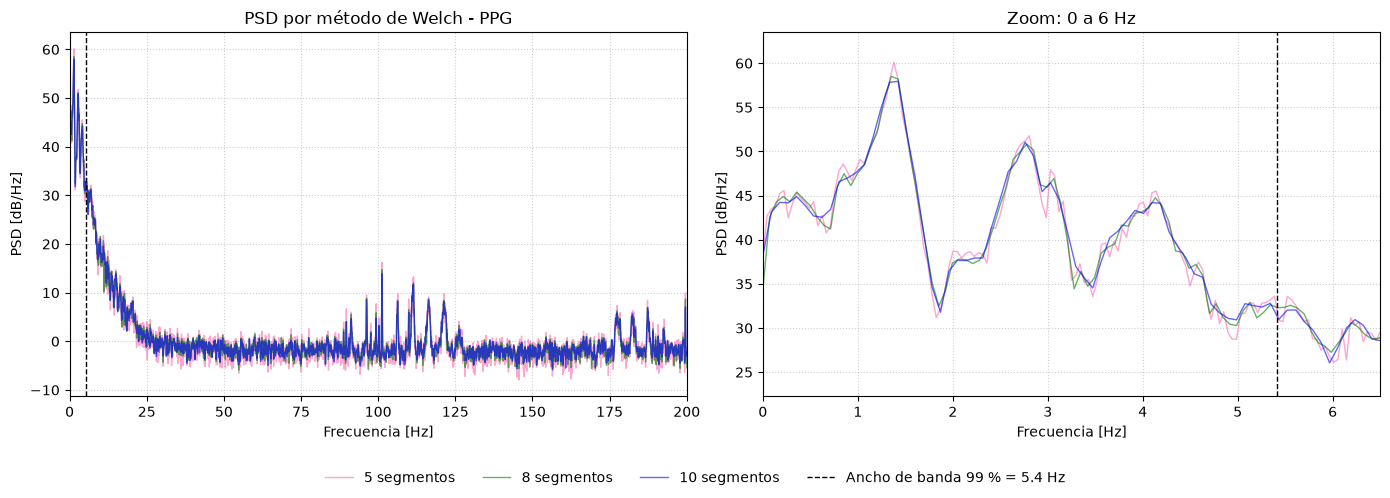

In [18]:
# Límite superior del zoom [Hz]: ajustalo mirando el primer gráfico
f_ppg_zoom = 1.2 * ancho_ppg_8
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for ax in (ax1, ax2):
    ax.plot(frec_ppg_5, pxx_db_ppg_5, color='hotpink', linewidth=1, alpha=0.6, label="5 segmentos")
    ax.plot(frec_ppg_8, pxx_db_ppg_8, color='green', linewidth=1, alpha=0.6, label="8 segmentos")
    ax.plot(frec_ppg_10, pxx_db_ppg_10, color='blue', linewidth=1, alpha=0.6, label="10 segmentos")
    ax.axvline(ancho_ppg_8, color='k', linestyle='--', linewidth=1,
               label=f'Ancho de banda 99 % = {ancho_ppg_8:.1f} Hz')
    ax.set_xlabel('Frecuencia [Hz]')
    ax.set_ylabel('PSD [dB/Hz]')
    ax.grid(True, linestyle=':', alpha=0.6)

# Gráfico 1: espectro completo
ax1.set_title('PSD por método de Welch - PPG')
ax1.set_xlim(0, fs_ppg / 2)

# Gráfico 2: zoom en los primeros picos
ax2.set_title(f'Zoom: 0 a {f_ppg_zoom:.0f} Hz')
ax2.set_xlim(0, f_ppg_zoom)
mask = frec_ppg_8 <= f_ppg_zoom   # reajusta el eje y al rango visible
ax2.set_ylim(pxx_db_ppg_8[mask].min() - 5, pxx_db_ppg_8[mask].max() + 5)

# Para poner una única leyenda debajo de los gráficos porque sino tapa información
handles, labels = ax1.get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=len(labels), frameon=False)
fig.tight_layout(rect=[0, 0.08, 1, 1])   # Para que la leyenda no quede pegada a los ejes
plt.show()

ancho_ppg_selec=ancho_ppg_8

En los gráficos se comparan las PSD estimadas con los tres valores de $K$. En ambas imágenes se agregó una línea que señala el ancho de banda que corresponde al $K$ elegido.<br>
En el zoom se observa que la estimación de $K=5$ cuenta con muchas fluctuaciones mientras que para $K=10$ la curva se ve más suavizada, es por esto que se eligió $K=8$. El ancho de banda obtenido es $5{,}4Hz$, pero además es importante notar que en el espectro completo se observan picos entre $90Hz$ y $125Hz$ que están a más de $40dB$ de los principales, por lo que su aporte a la potencia es muy bajo y no modifican el ancho de banda.

### Sonido
Se plantea el código para la toma de datos del *sonido* y su análisis:

In [22]:
#%% Sonido
####################
# Lectura de audio #
####################

fs_audio, wav_data = sio.wavfile.read('la cucaracha.wav')
# fs_audio, wav_data = sio.wavfile.read('prueba psd.wav')
# fs_audio, wav_data = sio.wavfile.read('silbido.wav')

# plt.figure()
# plt.plot(wav_data)

# si quieren oirlo, tienen que tener el siguiente módulo instalado
# pip install sounddevice
# import sounddevice as sd
# sd.play(wav_data, fs_audio)

# ================= Normalizo la potencia a 1W =================
wav_data=wav_data/np.sqrt(np.var(wav_data))
print("Wav data - Potencia del audio normalizado")
print(np.var(wav_data))
# ==============================================================
print("fs - audio")
print(fs_audio)
#%%% Diagrama espectral

#El número indica la cantidad de segmentos en los que se dividió el intervalo
#Por defecto usa la ventana Hann para ventanear los segmentos

frec_wav_30,pxx_wav_30=sig.welch(wav_data,fs_audio,nperseg=len(wav_data)//30)#Da segmentos de tamaño entero
#nperseg:largo de cada segmento.
frec_wav_50,pxx_wav_50=sig.welch(wav_data,fs_audio,nperseg=len(wav_data)//50)#Da segmentos de tamaño entero
frec_wav_40,pxx_wav_40=sig.welch(wav_data,fs_audio,nperseg=len(wav_data)//40)#Da segmentos de tamaño entero
#sig.welch devuelve potencia, así que para logaritmarlo no hay que elevar al cuadrado

pxx_db_wav_30=10*np.log10(pxx_wav_30)
pxx_db_wav_50=10*np.log10(pxx_wav_50)
pxx_db_wav_40=10*np.log10(pxx_wav_40)

#%%% Ancho de banda
"""
Usando este método del porcentaje de potencia es necesario aclarar que si hay mucho ruido en las frecuencias bajas y la información real está en las frecuencias altas, con este método parte de la información se va a perder
"""

#Devuelve la suma de valores a lo largo de un vector
pot_acum_nor_wav_30=np.cumsum(pxx_wav_30)/np.sum(pxx_wav_30) #Suma acumulativa en un vector/suma total. Lo normaliza
ancho_30=frec_wav_30[np.argmax(pot_acum_nor_wav_30>=0.99)] #acá se puede justificar con el rango audible y cómo recortaría yo más en un estilo pasabanda
#print(ancho_30)

pot_acum_nor_wav_40=np.cumsum(pxx_wav_40)/np.sum(pxx_wav_40) #Suma acumulativa en un vector/suma total. Lo normaliza
ancho_wav_40=frec_wav_40[np.argmax(pot_acum_nor_wav_40>=0.99)] #acá se puede justificar con el rango audible y cómo recortaría yo más en un estilo pasabanda
#print(ancho_40)

pot_acum_nor_wav_50=np.cumsum(pxx_wav_50)/np.sum(pxx_wav_50) #Suma acumulativa en un vector/suma total. Lo normaliza
ancho_wav_50=frec_wav_50[np.argmax(pot_acum_nor_wav_50>=0.99)] #acá se puede justificar con el rango audible y cómo recortaría yo más en un estilo pasabanda
#print(ancho_50)

Wav data - Potencia del audio normalizado
1.0
fs - audio
48000


Antes de estimar la PSD, la señal se normalizó para que tuviera potencia unitaria, dividiéndola por su desvío estándar $\left(\sigma\right)$ Como el ancho de banda se calcula a partir de la potencia acumulada normalizada, este paso no modifica el valor.<br>
En este último caso se estimó la PSD nuevamente por Welch para distintos $K$ hasta obtener tres valores convenientes para el análisis. Para esta señal se eligió $K=30$, $K=40$ y $K=50$:<br>
* $K=30\quad \rightarrow \quad L=4800$
* $K=40\quad \rightarrow \quad L=3600$
* $K=50\quad \rightarrow \quad L=2880$
<br> Igual que en ECG, los tres valores de $L$ son enteros, por lo que cubren el registro completo.<br>
Se utilizaron muchos más segmentos que para las señales anteriores porque el registro es corto pero tiene su potencia dividida en un rango de frecuencias mucho más amplio, por eso se puede trabajar con menor resolución $\Delta f=13{,}3Hz$ eligiendo el $K=40$ que muestra mejor compromiso entre los detalles en la señal y la varianza. El ancho de banda se definió seleccionando la primera frecuencia para la cual la potencia acumulada alcanza el $99\%$ de la potencia de la señal.

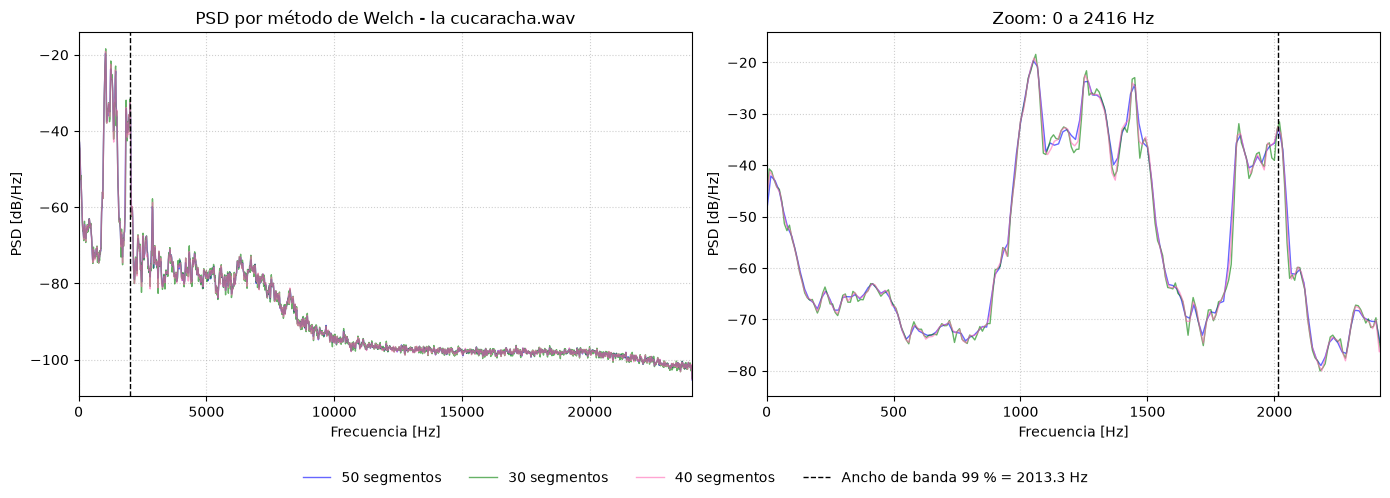

In [23]:
# Límite superior del zoom [Hz]: ajustalo mirando el primer gráfico
f_wav_zoom = 1.2 * ancho_wav_40
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for ax in (ax1, ax2):
    ax.plot(frec_wav_50, pxx_db_wav_50, color='blue', linewidth=1, alpha=0.6, label="50 segmentos")
    ax.plot(frec_wav_30, pxx_db_wav_30, color='green', linewidth=1, alpha=0.6, label="30 segmentos")
    ax.plot(frec_wav_40, pxx_db_wav_40, color='hotpink', linewidth=1, alpha=0.6, label="40 segmentos")
    ax.axvline(ancho_wav_40, color='k', linestyle='--', linewidth=1,
               label=f'Ancho de banda 99 % = {ancho_wav_40:.1f} Hz')
    ax.set_xlabel('Frecuencia [Hz]')
    ax.set_ylabel('PSD [dB/Hz]')
    ax.grid(True, linestyle=':', alpha=0.6)

# Gráfico 1: espectro completo
ax1.set_title('PSD por método de Welch - la cucaracha.wav')
ax1.set_xlim(0, fs_audio / 2)

# Gráfico 2: zoom en los primeros picos
ax2.set_title(f'Zoom: 0 a {f_wav_zoom:.0f} Hz')
ax2.set_xlim(0, f_wav_zoom)
mask = frec_wav_40 <= f_wav_zoom   # reajusta el eje y al rango visible
ax2.set_ylim(pxx_db_wav_40[mask].min() - 5, pxx_db_wav_40[mask].max() + 5)

# Para poner una única leyenda debajo de los gráficos porque sino tapa información
handles, labels = ax1.get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=len(labels), frameon=False)
fig.tight_layout(rect=[0, 0.08, 1, 1])   # Para que la leyenda no quede pegada a los ejes
plt.show()
ancho_sonido_selec=ancho_wav_40

Nuevamente, se comparan las PSD estimadas con los tres valores de $K$ y se agrega una línea indicando el ancho de banda para el $K$ seleccionado.
A diferencia de las señales anteriores, las tres curvas resultan muy similares entre sí, por lo que la elección del $K$ no resulta determinante. Se observa que la potencia se acumula entre los $1000$ y $1550Hz$ en una primera banda y luego entre los $1800$ y $2000Hz$, con picos bien definidos. Fuera de esos rangos, la PSD muestra frecuencias con potencias que se encuentran como mínimo $20dB$ por debajo de los picos principales.<br>
El ancho de banda obtenido es de $2013{,}3Hz$, sin embargo esto incluye el intervalo de $0Hz$ a $900Hz$, rango donde la potencia es muy baja por lo que la señal no ocupa todo el ancho. Esto muestra una limitación para el método, cuando la potencia de la señal no está concentrada cerca de $0Hz$, el ancho de banda obtenido sobreestima el rango de frecuencias que ocupa la señal.

In [24]:
#%% Tabla comparativa de ancho de banda

tabla = pd.DataFrame({
    'Señal':        ['ECG', 'PPG', 'Audio (la cucaracha.wav)'],
    'fs [Hz]':      [fs_ecg, fs_ppg, fs_audio],
    'BW 99 % [Hz]': [ancho_ecg_selec, ancho_ppg_selec, ancho_sonido_selec],
})
tabla['BW / (fs/2) [%]'] = 100 * tabla['BW 99 % [Hz]'] / (tabla['fs [Hz]'] / 2)
print("\nTabla Comparativa de BW:\n")
print(tabla.round(1).to_string(index=False))


Tabla Comparativa de BW:

                   Señal  fs [Hz]  BW 99 % [Hz]  BW / (fs/2) [%]
                     ECG     1000          30.7              6.1
                     PPG      400           5.4              2.7
Audio (la cucaracha.wav)    48000        2013.3              8.4


En la tabla se muestran los anchos de banda obtenidos para las tres señales con el valor de $K$ elegido en cada caso. El PPG presenta el menor ancho de banda $\left(5{,}4Hz\right)$, seguido del ECG $\left(30{,}7Hz\right)$ y luego el sonido $\left(2013{,}3Hz\right)$ superando a los dos anteriores en más de un orden de magnitud.<br>
En la última columna se muestra que el ancho de banda ocupa en todos los casos menos del $10\%$ de la banda digital ssegún el criterio por el que se optó en el proyecto, por lo que podría utilizarse una frecuencia de muestreo más baja para realizar el trabajo y ahorrar recursos.

# Conclusión
El método Welch permitió estimar la PSD de las tres señales con menor varianza que el periodograma, a partir del promedio de periodogramas de segmentos solapados. La elección de la cantidad de segmentos $K$ mostró el compromiso entre la resolución y la varianza, el cual resultó dependiente de cada señal. En el PPG, donde la potencia se concentra en frecuencias muy bajas, fue necesario priorizar la resolución. En el audio, donde la potencia se distribuye en un rango amplio, se pudo trabajar con una menor resolución sin que la elección de $K$ modificara notoriamente el resultado. El criterio del 99% de la potencia acumulada resultó simple de implementar y cumplió con los requerimientos para componentes de baja potencia. Sin embargo, al medir el ancho de banda desde los $0Hz$, sobreestima el rango ocupado por señales con la potencia en intervalos mayores, como el audio analizado. Para este tipo de señales sería más adecuado definir un límite inferior para poder expresar un ancho de banda más riguroso.<br> Por último, los anchos de banda de las tres señales obtenidos ocupan menos del $10\%$ de la banda disponible, lo que muestra que las frecuencias de muestreo utilizadas son superiores a las necesarias para el criterio elegido.